In [68]:
!pip install matplotlib

Looking in indexes: https://pypi.org/simple, https://pypi.ngc.nvidia.com


In [1]:
import numpy as np

In [31]:
import pandas as pd

In [49]:
import math

In [69]:
import matplotlib.pyplot as plt

In [2]:
euler = 2.71828

## Categorias
1 - Spam
0 - Não Spam

In [35]:
dados = pd.DataFrame( {
    "X1": [3, 0, 6, 2], # Quantidade de palavras suspeitas
    "X2": [1, 2, 5, 3], # Quantidade de links
    "Y": [0, 0, 1, 1]   # Spam ou Não Spam
})
dados

,X1,X2,Y
0,3,1,0
1,0,2,0
2,6,5,1
3,2,3,1


In [25]:
x1 = 3  # Quantidade de palavras suspeitas
x2 = 2  # Quantidade de links
# x3 = 1  # Propaganda 1 - Propaganda   0 - Não propaganda

In [51]:
dados.shape

(4, 3)

In [28]:
def sigmoid( z ):
    return 1.0 / (1.0 + (euler ** (-z)))

In [71]:
w1 = 0.8
w2 = 0.5
b = -2
print(f"W1: {w1}\tW2: {w2}\tB: {b}")
m = dados.shape[0]
ciclos = 20
alpha = 0.01
historico_loss = []

for ciclo in range(ciclos):
    custo = 0
    erro_total = 0
    erro_total_w1 = 0
    erro_total_w2 = 0
    for linha in dados.iloc:
        x1 = linha["X1"]
        x2 = linha["X2"]
        y = linha["Y"]
        z = w1 * x1 + w2 * x2 + b   # Calculo da soma ponderada
        p_hat = sigmoid( z )   # Aplicado o Sigmoid
        y_hat = 1 if p_hat > 0.6 else 0
    
        # −[y ln(p_hat) + (1 − y) ln(1 − p_hat)] 
        erro = ((y *  math.log(p_hat)) + ((1 - y) * math.log(1 - p_hat)))
        custo = custo + erro   # Calcular o erro
        # print(f"x1: {x1}\tx2: {x2}\ty: {y}\tp_hat: {p_hat}\ty_hat: {y_hat}\terro: {erro}")
    
        # Soma de erros do w1
        # 𝜕J/(𝜕w_j )  = 1/m ∑(i=1 até m)(p_hat_i - y_i)x_ij
        erro_total += (p_hat - y)
        erro_total_w1 += erro_total * x1
        erro_total_w2 += erro_total * x2
    
        # Calcular a derivada ==> 𝜎′(z)=𝜎(z)(1 −𝜎(z))
        # dSigmoid = sigmoid(z) * (1 - sigmoid(z))
        # print(dSigmoid)
        
    # Calcular a função de custo
    loss = -(custo / m)   # Custo / Quantidade de linhas
    historico_loss.append(loss)
    print(f"Loss: {loss:f}")
    
    dB = erro_total / m
    dW1 = erro_total_w1 / m
    dW2 = erro_total_w2 / m
    
    w1 = w1 - (alpha * dW1)
    w2 = w2 - (alpha * dW2)
    b = b - (alpha * dB)
    
    print(f"W1: {w1}\tW2: {w2}\tB: {b}")

W1: 0.8	W2: 0.5	B: -2
Loss: 0.461683
W1: 0.7764180975771804	W2: 0.4756977398916806	B: -2.0018129601988175
Loss: 0.449724
W1: 0.7537380349957556	W2: 0.4524051164529059	B: -2.0034881145235897
Loss: 0.439627
W1: 0.7319532561651134	W2: 0.4301131187295444	B: -2.005025643499645
Loss: 0.431291
W1: 0.7110542613494193	W2: 0.40880940019549517	B: -2.0064263773400444
Loss: 0.424607
W1: 0.6910290324627254	W2: 0.38847873362144153	B: -2.007691735581553
Loss: 0.419464
W1: 0.6718634841578648	W2: 0.36910350391630636	B: -2.008823653736467
Loss: 0.415747
W1: 0.6535419045061126	W2: 0.3506641991200332	B: -2.0098245037522973
Loss: 0.413343
W1: 0.6360473539692946	W2: 0.3331398645553324	B: -2.010697014635863
Loss: 0.412138
W1: 0.6193619988281456	W2: 0.3165084929288705	B: -2.011444198561082
Loss: 0.412022
W1: 0.6034673641916863	W2: 0.30074733271192705	B: -2.0120692863555996
Loss: 0.412887
W1: 0.588344501135731	W2: 0.28583310724993494	B: -2.0125756746700376
Loss: 0.414629
W1: 0.5739740714727833	W2: 0.27174214670

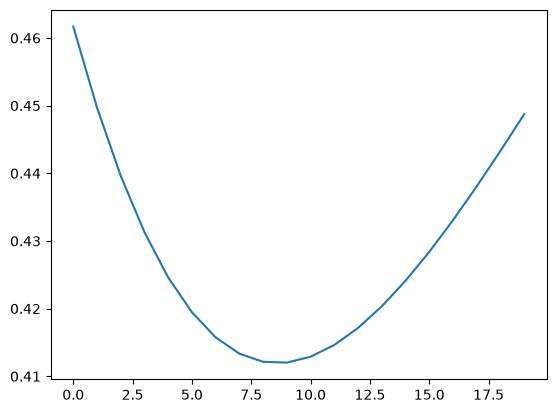

In [72]:
plt.plot(historico_loss)